# Keeping What Matters

*The Mathematics of Machine Intelligence · Chapter 3*

Spend a few distinguishable signal steps where the world is crowded, and see what that rule does not say.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask how many distinguishable levels the channel has, how the inputs are distributed, and what the next stage does with the signal. Use the entropy ceiling for the most bits, the share-at-or-below rule when the goal is to tell inputs apart, the squared-error layout when a later stage must rebuild the input, and the sparse objective when few active elements are wanted. For a screening or alerting tool, convert reported rates into counts before judging it.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 3, Keeping What Matters: executable mathematics and reader-facing teaching content."""
import math
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 11)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)

def entropy_bits(p):
    """Shannon entropy in bits; zero-probability terms count as zero."""
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())
LEVELS = 10

def step_use(band_steps, band_readings=800, total=1000, levels=LEVELS):
    """Share of readings landing in each of `levels` evenly spaced steps.

    The narrow central band (band_readings of `total`) spreads evenly over band_steps steps; the rest
    spread evenly over the remaining steps. With band_steps = 8 and 800 of 1000 this is the chapter's
    equal-use layout, 100 readings per step.
    """
    if not 1 <= band_steps <= levels - 1:
        raise ValueError('The band must cover between 1 and levels - 1 steps.')
    p = np.empty(levels)
    p[:band_steps] = band_readings / total / band_steps
    p[band_steps:] = (total - band_readings) / total / (levels - band_steps)
    return p

def bits_picture(band_steps=2, band_readings=800):
    p = step_use(band_steps, band_readings)
    h = entropy_bits(p)
    h_max = math.log2(LEVELS)
    n_tail = LEVELS - band_steps
    left = n_tail // 2
    order = np.concatenate([p[band_steps:band_steps + left], p[:band_steps], p[band_steps + left:]])
    kinds = ['tail'] * left + ['band'] * band_steps + ['tail'] * (n_tail - left)
    fig, ax = panels()
    ax[0].bar(range(1, LEVELS + 1), order, color=[TEAL if k == 'band' else TERRA for k in kinds], width=0.7)
    ax[0].axhline(1 / LEVELS, color=GREY, linestyle='dashed', linewidth=1.2)
    tag(ax[0], LEVELS + 0.45, 1 / LEVELS, 'equal use', fontsize=9, ha='right', va='bottom', color=GREY)
    ax[0].set(xlabel='step, from lowest contrast to highest', ylabel='share of the readings', xticks=range(1, LEVELS + 1), title=f'The band covers {band_steps} of {LEVELS} steps', ylim=(0, 1.0))
    ks = np.arange(1, LEVELS)
    curve = [entropy_bits(step_use(int(k), band_readings)) for k in ks]
    ax[1].plot(ks, curve, color=NAVY, marker='o', markersize=5)
    ax[1].axhline(h_max, color=GREY, linestyle='dashed', linewidth=1.2)
    tag(ax[1], 1.3, h_max, f'most possible, {sig(h_max)} bits', fontsize=9, ha='left', va='bottom', color=GREY)
    ring(ax[1], band_steps, h)
    ax[1].set(xlabel='steps that the narrow band covers', ylabel='bits carried per signal', ylim=(0, h_max + 0.6), title='Only the right layout uses them all', xticks=ks)
    metrics = {'Bits carried': sig(h), 'Most possible, log2 10': sig(h_max), 'Share of the most': f'{100 * h / h_max:.0f} percent', 'Busiest step': f'{100 * p.max():.0f} percent of readings'}
    even = abs(h - h_max) < 1e-09
    if even:
        summary = f"Every step carries {sig(100 / LEVELS)} percent of the readings, so the ten levels carry the full {sig(h_max)} bits. This is the chapter's equal-use layout: eight fine steps in the band and one in each tail."
    else:
        summary = f'With the band covering {band_steps} steps, the busiest step holds {100 * p.max():.0f} percent of the readings and the ten levels carry {sig(h)} of a possible {sig(h_max)} bits. Placement of the steps, not their number, set the shortfall.'
    calc = f'Shares: band steps {sig(band_readings / 1000 / band_steps)} each, tail steps {sig((1000 - band_readings) / 1000 / n_tail)} each. H = -sum p log2 p = {sig(h)} bits against log2 10 = {sig(h_max)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def laplace_cdf(c, scale=1.0):
    c = np.asarray(c, dtype=float)
    return np.where(c < 0, 0.5 * np.exp(np.minimum(c, 0) / scale), 1 - 0.5 * np.exp(-np.maximum(c, 0) / scale))

def linear_use(half_range, levels=LEVELS, scale=1.0):
    """Output-step probabilities when response is linear in contrast over [-half_range, half_range] and clipped.

    Clipped contrasts fall in the end steps. Contrast follows a Laplace distribution with the given scale.
    """
    edges = np.linspace(-half_range, half_range, levels + 1)
    cdf = laplace_cdf(edges, scale)
    return np.diff(np.concatenate([[0.0], cdf[1:-1], [1.0]]))

def cdf_rule_use(levels=LEVELS):
    """With r = rmax F(c), every equal-width response step is used 1 / levels of the time."""
    return np.full(levels, 1.0 / levels)
RANGES = [0.5, 1, 2, 3, 5, 8]

def cumulative_rule_picture(half_range=3, levels=10):
    h_lin = entropy_bits(linear_use(half_range, levels))
    h_max = math.log2(levels)
    clipped = math.exp(-half_range)
    fig, ax = panels()
    c = np.linspace(-6, 6, 600)
    twin = ax[0].twinx()
    twin.fill_between(c, 0.5 * np.exp(-np.abs(c)), color=GOLD, alpha=0.35)
    twin.set_ylim(0, 2.2)
    twin.set_yticks([])
    twin.spines['right'].set_visible(False)
    ax[0].plot(c, laplace_cdf(c), color=TEAL, linewidth=2.6, label='share at or below, r = rmax F(c)')
    ax[0].plot(c, np.clip((c + half_range) / (2 * half_range), 0, 1), color=TERRA, linewidth=2.2, linestyle='dashed', label='evenly spaced steps')
    ax[0].set_zorder(twin.get_zorder() + 1)
    ax[0].patch.set_visible(False)
    ax[0].set(xlabel='contrast (constructed Laplace world, scale 1)', ylabel='response / top response', ylim=(-0.02, 1.02), xlim=(-6, 6), title='Gold: how often a contrast occurs')
    ax[0].legend(fontsize=8, loc='upper left')
    grid = np.array(RANGES, dtype=float)
    ax[1].plot(grid, [entropy_bits(linear_use(L, levels)) for L in grid], color=TERRA, marker='o', markersize=5, label='evenly spaced steps')
    ax[1].axhline(h_max, color=TEAL, linewidth=2.4, label='share-at-or-below rule')
    ring(ax[1], half_range, h_lin)
    ax[1].set(xscale='log', xlabel='half-range of the response (contrast units)', ylabel='bits carried per signal', ylim=(0, h_max + 0.8), xticks=RANGES, title='Too sensitive or too blunt wastes steps')
    ax[1].set_xticklabels([f'{g:g}' for g in RANGES])
    ax[1].minorticks_off()
    ax[1].legend(fontsize=8, loc='lower center')
    metrics = {'Bits, evenly spaced': sig(h_lin), 'Bits, share rule': sig(h_max), 'Readings clipped at an end': f'{100 * clipped:.0f} percent', 'Levels': levels}
    note = 'mostly clipped at the ends' if half_range < 1.5 else 'mostly idle at the ends' if half_range > 3.5 else 'a middling compromise'
    summary = f'With a half-range of {half_range:g} the evenly spaced response carries {sig(h_lin)} of {sig(h_max)} bits and is {note}. The share-at-or-below curve uses every step {sig(100 / levels)} percent of the time for any scale of world.'
    calc = f'Clipped fraction = exp(-{half_range:g}) = {sig(clipped)}. Entropy of the {levels} step probabilities = {sig(h_lin)} bits; the rule gives log2 {levels} = {sig(h_max)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def _mass_edges(x):
    return laplace_cdf(x)

def _first_moment(x):
    """Integral of t f(t) dt from minus infinity to x for the Laplace density f(t) = exp(-|t|) / 2."""
    x = np.asarray(x, dtype=float)
    return np.where(x < 0, 0.5 * np.exp(np.minimum(x, 0)) * (x - 1), -0.5 * (np.maximum(x, 0) + 1) * np.exp(-np.maximum(x, 0)))

def _second_moment(x):
    """Integral of t^2 f(t) dt from minus infinity to x."""
    x = np.asarray(x, dtype=float)
    neg = 0.5 * np.exp(np.minimum(x, 0)) * (x ** 2 - 2 * x + 2)
    pos = 2 - 0.5 * (np.maximum(x, 0) ** 2 + 2 * np.maximum(x, 0) + 2) * np.exp(-np.maximum(x, 0))
    return np.where(x < 0, neg, pos)

def cell_stats(edges):
    """Probability, centroid and squared-error contribution of each cell between consecutive edges (end edges +-inf)."""
    edges = np.asarray(edges, dtype=float)
    hi, lo = (edges[1:], edges[:-1])
    f_hi = np.where(np.isposinf(hi), 1.0, _mass_edges(np.where(np.isposinf(hi), 0.0, hi)))
    f_lo = np.where(np.isneginf(lo), 0.0, _mass_edges(np.where(np.isneginf(lo), 0.0, lo)))
    m_hi = np.where(np.isposinf(hi), 0.0, _first_moment(np.where(np.isposinf(hi), 0.0, hi)))
    m_lo = np.where(np.isneginf(lo), 0.0, _first_moment(np.where(np.isneginf(lo), 0.0, lo)))
    s_hi = np.where(np.isposinf(hi), 2.0, _second_moment(np.where(np.isposinf(hi), 0.0, hi)))
    s_lo = np.where(np.isneginf(lo), 0.0, _second_moment(np.where(np.isneginf(lo), 0.0, lo)))
    mass, first, second = (f_hi - f_lo, m_hi - m_lo, s_hi - s_lo)
    centroid = first / mass
    sq_err = second - 2 * centroid * first + centroid ** 2 * mass
    return (mass, centroid, sq_err)

def laplace_quantile(u):
    u = np.asarray(u, dtype=float)
    return np.where(u < 0.5, np.log(2 * u), -np.log(2 * (1 - u)))

def equal_use_edges(levels):
    """Interior boundaries that give every step the same probability, plus +-inf ends."""
    return np.concatenate([[-np.inf], laplace_quantile(np.arange(1, levels) / levels), [np.inf]])

def squared_error_edges(levels, sweeps=4000):
    """Lloyd-Max boundaries for the Laplace density: repeat 'level = centroid, boundary = midpoint' to convergence."""
    edges = equal_use_edges(levels)
    for _ in range(sweeps):
        _, centroid, _ = cell_stats(edges)
        new = np.concatenate([[-np.inf], 0.5 * (centroid[:-1] + centroid[1:]), [np.inf]])
        if np.max(np.abs(new[1:-1] - edges[1:-1])) < 1e-13:
            edges = new
            break
        edges = new
    return edges

def design_summary(levels, design):
    edges = equal_use_edges(levels) if design == 'equal use' else squared_error_edges(levels)
    mass, centroid, sq_err = cell_stats(edges)
    return {'edges': edges, 'mass': mass, 'centroid': centroid, 'mse': float(sq_err.sum()), 'bits': entropy_bits(mass)}
LEVEL_COUNTS = [4, 6, 8, 10, 12, 16]
DESIGNS = ['equal use', 'squared error']

def quantizer_picture(levels=10, design='equal use'):
    chosen = design_summary(levels, design)
    fig, ax = panels()
    x = np.linspace(-7, 7, 600)
    ax[0].fill_between(x, 0.5 * np.exp(-np.abs(x)), color=GOLD, alpha=0.4)
    for row, (name, colour, y) in enumerate([('equal use', TEAL, 0.0), ('squared error', TERRA, -0.07)]):
        e = design_summary(levels, name)['edges'][1:-1]
        e = e[np.abs(e) < 7]
        ax[0].plot(e, np.full(len(e), y), linestyle='none', marker='|', markersize=16 if name == design else 11, markeredgewidth=3 if name == design else 1.6, color=colour, label=name)
    ax[0].set(xlabel='contrast (Laplace, scale 1)', ylabel='density', xlim=(-7, 7), ylim=(-0.12, 0.55), title=f'Step boundaries, {levels} steps')
    ax[0].legend(fontsize=9, loc='upper right')
    grid = np.array(LEVEL_COUNTS)
    for name, colour, marker in [('equal use', TEAL, 'o'), ('squared error', TERRA, 's')]:
        ax[1].plot(grid, [design_summary(int(m), name)['mse'] for m in grid], color=colour, marker=marker, markersize=5, label=name)
    ring(ax[1], levels, chosen['mse'])
    ax[1].set(yscale='log', xlabel='number of steps', ylabel='mean squared error', title='The two goals give two layouts', xticks=LEVEL_COUNTS, yticks=[0.03, 0.05, 0.1, 0.2, 0.5])
    ax[1].set_yticklabels(['0.03', '0.05', '0.1', '0.2', '0.5'])
    ax[1].minorticks_off()
    ax[1].legend(fontsize=9, loc='upper right')
    other = design_summary(levels, 'squared error' if design == 'equal use' else 'equal use')
    outer = float(chosen['edges'][-2])
    metrics = {'Outermost boundary': sig(outer), 'Bits carried': sig(chosen['bits']), 'Squared error': sig(chosen['mse']), 'Squared error of the other layout': sig(other['mse'])}
    summary = f"With {levels} steps, the {design} layout puts its outermost boundary at {sig(outer)} and has squared error {sig(chosen['mse'])}, against {sig(other['mse'])} for the other layout. Equal use carries {sig(math.log2(levels))} bits; the squared-error layout trades some of that for a smaller miss on large contrasts."
    calc = 'Equal-use boundaries are the quantiles F^-1(k / M), where F^-1(u) = ln(2u) for u below 0.5 and -ln(2(1 - u)) above. Squared-error boundaries sit midway between neighboring centroids at convergence.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def normal_cdf(z):
    z = np.asarray(z, dtype=float)
    return 0.5 * (1.0 + np.vectorize(math.erf)(z / math.sqrt(2.0)))

def rescaled_bits(width, spread, levels=LEVELS):
    """Bits carried by `levels` equal response steps when velocity ~ Normal(0, spread) and the response is logistic(v / width).

    Depends only on width / spread.
    """
    inner = np.arange(1, levels) / levels
    v_edges = width * np.log(inner / (1 - inner))
    cdf = normal_cdf(v_edges / spread)
    return entropy_bits(np.diff(np.concatenate([[0.0], cdf, [1.0]])))

def best_width_ratio(levels=LEVELS):
    """The width / spread ratio that carries the most bits, by fine grid search."""
    grid = np.linspace(0.05, 3.0, 5800)
    bits = [rescaled_bits(g, 1.0, levels) for g in grid]
    return float(grid[int(np.argmax(bits))])
SPREADS = [2, 4, 8]
WIDTHS = [0.5, 1, 2, 3, 4, 6, 8, 12]

def rescaling_picture(spread=4, width=2):
    best_ratio = best_width_ratio()
    best_width = best_ratio * spread
    h = rescaled_bits(width, spread)
    h_best = rescaled_bits(best_width, spread)
    fig, ax = panels()
    v = np.linspace(-3.2 * max(SPREADS), 3.2 * max(SPREADS), 800)
    twin = ax[0].twinx()
    twin.fill_between(v, np.exp(-0.5 * (v / spread) ** 2) / (spread * math.sqrt(2 * math.pi)), color=GOLD, alpha=0.35)
    twin.set_ylim(0, 0.6 / min(SPREADS) * 1.6)
    twin.set_yticks([])
    twin.spines['right'].set_visible(False)
    ax[0].plot(v, 1 / (1 + np.exp(-v / width)), color=TERRA, linewidth=2.4, label=f"cell's curve, width {width:g}")
    ax[0].plot(v, 1 / (1 + np.exp(-v / best_width)), color=TEAL, linewidth=2, linestyle='dashed', label=f'best width for this spread, {sig(best_width)}')
    ax[0].set_zorder(twin.get_zorder() + 1)
    ax[0].patch.set_visible(False)
    ax[0].set(xlabel='velocity (arbitrary units; gold shape is how often)', ylabel='response / top response', xlim=(-30, 30), title=f'Velocity spread {spread}')
    ax[0].legend(fontsize=8, loc='upper left')
    ratios = np.linspace(0.05, 6, 300)
    colours = {2: TERRA, 4: GOLD, 8: TEAL}
    for s in SPREADS:
        ax[1].plot(ratios, [rescaled_bits(r * s, s) for r in ratios], color=colours[s], linewidth=3.6 if s == 2 else 2.4 if s == 4 else 1.4, linestyle={2: 'solid', 4: 'dashed', 8: 'dotted'}[s], label=f'spread {s}')
    ring(ax[1], width / spread, h)
    ax[1].axvline(best_ratio, color=GREY, linestyle='dashed', linewidth=1)
    tag(ax[1], best_ratio + 0.1, 1.4, 'best ratio', fontsize=9, ha='left', color=GREY)
    tag(ax[1], 4.0, 2.9, 'the three curves lie\nexactly on top of each other', fontsize=9)
    ax[1].set(xlabel='curve width / velocity spread', ylabel='bits carried per signal', title='Three spreads, one curve', ylim=(1.0, math.log2(LEVELS) + 0.1))
    ax[1].legend(fontsize=8, loc='center right')
    metrics = {'Bits carried': sig(h), 'Bits at the best width': sig(h_best), 'Width / spread': sig(width / spread), 'Best width / spread': sig(best_ratio)}
    summary = f'At spread {spread} a curve of width {width:g} carries {sig(h)} bits, against {sig(h_best)} at the best width, {sig(best_width)}. The best width is {sig(best_ratio)} times the spread whatever the spread, so the curve must stretch in proportion.'
    calc = f"Boundaries in velocity are width x ln(k/(10 - k)); each step's probability is a difference of normal cumulative values at boundary / {spread}. Width / spread = {sig(width / spread)} gives {sig(h)} bits."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def total_cost(error, penalty, lam):
    return error + lam * penalty
LAMBDAS = [0, 0.1, 0.25, 0.5, 1, 2, 4]
ERRORS = [2, 3, 4]

def sparse_cost_picture(lam=1, sparse_error=2):
    exact = (1.0, 4.0)
    sparse = (float(sparse_error), 1.0)
    cost_a = total_cost(*exact, lam)
    cost_b = total_cost(*sparse, lam)
    crossing = (sparse[0] - exact[0]) / (exact[1] - sparse[1])
    fig, ax = panels()
    for i, (name, (err, pen), cost) in enumerate([('exact\nrebuild', exact, cost_a), ('sparse\nrebuild', sparse, cost_b)]):
        ax[0].bar(i, err, color=TEAL, width=0.55, label='squared error' if i == 0 else None)
        ax[0].bar(i, lam * pen, bottom=err, color=GOLD, width=0.55, label='lambda x penalty' if i == 0 else None)
        tag(ax[0], i, cost + 0.35, sig(cost), fontsize=12, va='bottom')
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['exact\nrebuild', 'sparse\nrebuild'])
    ax[0].set(ylabel='cost E', ylim=(0, 18), title=f"lambda = {lam:g}: {('sparse' if cost_b < cost_a else 'exact')} rebuild wins" if cost_a != cost_b else f'lambda = {lam:g}: a tie')
    ax[0].legend(fontsize=9, loc='upper left')
    grid = np.linspace(0, 4, 100)
    ax[1].plot(grid, total_cost(*exact, grid), color=NAVY, label='exact rebuild (error 1, penalty 4)')
    ax[1].plot(grid, total_cost(*sparse, grid), color=TERRA, label=f'sparse rebuild (error {sparse_error}, penalty 1)')
    ax[1].plot([crossing], [total_cost(*exact, crossing)], marker='D', color=GREY, markersize=7, linestyle='none')
    tag(ax[1], crossing + 0.1, total_cost(*exact, crossing) - 1.3, f'cross at {sig(crossing)}', fontsize=9, ha='left', color=GREY)
    ring(ax[1], lam, min(cost_a, cost_b))
    ax[1].set(xlabel='lambda, the weight on the penalty', ylabel='cost E', ylim=(0, 18), title='Which code is cheaper depends on lambda')
    ax[1].legend(fontsize=8, loc='upper left')
    winner = 'sparse rebuild' if cost_b < cost_a else 'exact rebuild' if cost_a < cost_b else 'tie'
    metrics = {'Cost, exact rebuild': sig(cost_a), 'Cost, sparse rebuild': sig(cost_b), 'Cheaper': winner, 'Crossover lambda': sig(crossing)}
    summary = f'At lambda {lam:g} the exact rebuild costs {sig(cost_a)} and the sparse rebuild costs {sig(cost_b)}, so the model prefers the {winner}. The two cost the same at lambda = {sig(crossing)}; the less exact code wins above that.'
    calc = f'Exact: 1 + {lam:g} x 4 = {sig(cost_a)}. Sparse: {sparse_error} + {lam:g} x 1 = {sig(cost_b)}. Crossover: 1 + 4 L = {sparse_error} + L gives L = {sig(crossing)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PATCH_COEFFS = np.array([3.0, -2.2, 1.4, 0.9, -0.6, 0.35, 0.2, -0.1])
PENALTIES = ['absolute value', 'square']

def sparse_code(coeffs, lam, penalty='absolute value'):
    """Minimizer of sum (c - a)^2 + lam * S(a) for an orthonormal dictionary.

    S(a) = |a| gives soft thresholding, a = sign(c) max(|c| - lam / 2, 0). S(a) = a^2 gives a = c / (1 + lam).
    """
    c = np.asarray(coeffs, dtype=float)
    if penalty == 'absolute value':
        return np.sign(c) * np.maximum(np.abs(c) - lam / 2.0, 0.0)
    if penalty == 'square':
        return c / (1.0 + lam)
    raise ValueError("penalty must be 'absolute value' or 'square'")

def objective(coeffs, a, lam, penalty):
    s = np.abs(a) if penalty == 'absolute value' else a ** 2
    return float(np.sum((np.asarray(coeffs) - a) ** 2) + lam * np.sum(s))
SPARSITY_LAMBDAS = [0, 0.5, 1, 2, 3, 4, 6, 8, 10]

def sparse_toy_picture(lam=2, penalty='absolute value'):
    a = sparse_code(PATCH_COEFFS, lam, penalty)
    error = float(np.sum((PATCH_COEFFS - a) ** 2))
    active = int(np.sum(np.abs(a) > 1e-12))
    total = objective(PATCH_COEFFS, a, lam, penalty)
    fig, ax = panels()
    idx = np.arange(len(PATCH_COEFFS))
    ax[0].bar(idx - 0.2, PATCH_COEFFS, width=0.38, color=GREY, label='needed (patch coefficients)')
    ax[0].bar(idx + 0.2, a, width=0.38, color=TEAL, label='used (code)')
    ax[0].axhline(0, color=GREY, linewidth=0.8)
    ax[0].set(xlabel='dictionary element', ylabel='strength', xticks=idx, xticklabels=[str(i + 1) for i in idx], title=f'{active} of 8 elements active', ylim=(-3.6, 5.2))
    ax[0].legend(fontsize=8, loc='upper right')
    for name, colour, marker in [('absolute value', TEAL, 'o'), ('square', TERRA, 's')]:
        pts = []
        for L in SPARSITY_LAMBDAS:
            code = sparse_code(PATCH_COEFFS, L, name)
            pts.append((int(np.sum(np.abs(code) > 1e-12)), float(np.sum((PATCH_COEFFS - code) ** 2))))
        pts = np.array(pts)
        ax[1].plot(pts[:, 0] + (0.07 if name == 'square' else -0.07), pts[:, 1], color=colour, marker=marker, markersize=5, linestyle='dotted' if name == 'square' else 'solid', label=f'penalty: {name}')
    ring(ax[1], active, error)
    ax[1].set(xlabel='elements in use', ylabel='squared reconstruction error', title='Error paid for each element dropped', xticks=range(0, 9))
    ax[1].legend(fontsize=8, loc='upper right')
    metrics = {'Elements active': active, 'Squared error': sig(error), 'Total cost E': sig(total), 'Energy in the patch': sig(np.sum(PATCH_COEFFS ** 2))}
    if penalty == 'absolute value':
        summary = f'With the absolute-value penalty and lambda {lam:g}, every coefficient smaller than lambda/2 = {sig(lam / 2)} is dropped and the rest shrink by that amount. {active} of 8 elements stay active at a squared error of {sig(error)}.'
    else:
        summary = f'With a squared penalty and lambda {lam:g}, every coefficient shrinks by the same factor 1/(1 + {lam:g}) = {sig(1 / (1 + lam))} and none reaches zero, so all {active} elements stay active. A penalty that grows this fast with strength does not make the code sparse.'
    calc = f"Squared error = {sig(error)}, penalty term = {sig(lam)} x {sig(np.sum(np.abs(a)) if penalty == 'absolute value' else np.sum(a ** 2))}, total E = {sig(total)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
EXAMS, CANCERS = (625625, 3159)
CANCER_RATE = CANCERS / EXAMS
BASE_SENS, BASE_SPEC = (87.3, 91.0)

def screening_counts(sensitivity, specificity, rate=CANCER_RATE, exams=100000):
    """Expected counts per `exams` examinations (sensitivity and specificity in percent)."""
    cancers = rate * exams
    found = cancers * sensitivity / 100.0
    missed = cancers - found
    false_recalls = (exams - cancers) * (1 - specificity / 100.0)
    return {'cancers': cancers, 'found': found, 'missed': missed, 'false_recalls': false_recalls, 'recalls': found + false_recalls, 'recall_percent': 100.0 * (found + false_recalls) / exams}
SENSITIVITIES = [80.0, 85.3, 87.3, 90.0]
SPECIFICITIES = [87.2, 90.2, 91.0, 93.0]

def screening_picture(sensitivity=85.3, specificity=91.0):
    d = screening_counts(sensitivity, specificity)
    base = screening_counts(BASE_SENS, BASE_SPEC)
    fig, ax = panels()
    labels = ['cancers found', 'cancers missed', 'recalled, no cancer']
    values = [d['found'], d['missed'], d['false_recalls']]
    ax[0].barh(range(3), values, color=[TEAL, TERRA, GOLD], height=0.6)
    ax[0].set_xscale('log')
    ax[0].set_xlim(30, 40000)
    ax[0].set_yticks(range(3))
    ax[0].set_yticklabels(labels)
    ax[0].invert_yaxis()
    for i, v in enumerate(values):
        tag(ax[0], v * 1.15, i, f'{v:,.0f}', fontsize=10, ha='left', va='center')
    ax[0].set(xlabel='per 100,000 screening exams (log scale)', title='Expected counts')
    for s in SENSITIVITIES:
        for p in SPECIFICITIES:
            c = screening_counts(s, p)
            ax[1].plot(c['found'] - base['found'], c['false_recalls'] - base['false_recalls'], marker='o', color=GREY, alpha=0.5, markersize=5, linestyle='none')
    ax[1].plot([0], [0], marker='D', color=NAVY, markersize=7, linestyle='none')
    tag(ax[1], 1.5, 350, 'baseline', fontsize=9, ha='left', va='bottom', color=NAVY)
    ring(ax[1], d['found'] - base['found'], d['false_recalls'] - base['false_recalls'])
    ax[1].axhline(0, color=GREY, linewidth=0.8)
    ax[1].axvline(0, color=GREY, linewidth=0.8)
    ax[1].set(xlabel='change in cancers found, per 100,000', ylabel='change in no-cancer recalls, per 100,000', title='Finds move by tens, recalls by thousands')
    metrics = {'Cancers found': f"{d['found']:,.0f}", 'Cancers missed': f"{d['missed']:,.0f}", 'Recalled with no cancer': f"{d['false_recalls']:,.0f}", 'Recall rate': f"{d['recall_percent']:.1f} percent"}
    summary = f"At sensitivity {sensitivity:g} and specificity {specificity:g} the arithmetic gives about {d['found']:,.0f} cancers found and {d['false_recalls']:,.0f} no-cancer recalls per 100,000 exams, a recall rate of {d['recall_percent']:.1f} percent. Against the baseline, finds change by {d['found'] - base['found']:+,.0f} and no-cancer recalls by {d['false_recalls'] - base['false_recalls']:+,.0f}."
    calc = f"Cancer rate = 3,159 / 625,625 = {sig(CANCER_RATE)}. Cancers per 100,000 = {d['cancers']:,.0f}. Found = {d['cancers']:,.0f} x {sensitivity / 100:g} = {d['found']:,.0f}. No-cancer recalls = {100000 - d['cancers']:,.0f} x {sig(1 - specificity / 100)} = {d['false_recalls']:,.0f}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C03-D01: How many bits can ten steps carry, and when do they carry them all?

A cell can signal ten distinguishable levels. If most readings crowd into a narrow band, how much of the 3.32 bits does an evenly spaced layout waste?

A level that is used rarely adds little to what the signal can tell you, and a level that is used all the time cannot tell you which of the crowded readings occurred. Entropy averages the surprise of each level weighted by its share, and it is largest when the shares are equal. The ceiling log2 M is therefore a statement about use, not about how many levels there are.

$$
H_{\max}=\log_2 M,\qquad H=-\sum_{i=1}^{M}p_i\log_2 p_i\le\log_2 M
$$

**Symbols:** M: number of distinguishable levels (10 here); p_i: share of readings that land in level i; H: bits actually carried per signal, on average; H_max: the most any use of M levels can carry, reached when all p_i equal 1/M

**Predict before looking:** With 800 of 1,000 readings in a band that evenly spaced steps cover with only 2 of the 10 steps, predict to the nearest bit how many of the 3.32 possible bits the signal carries.

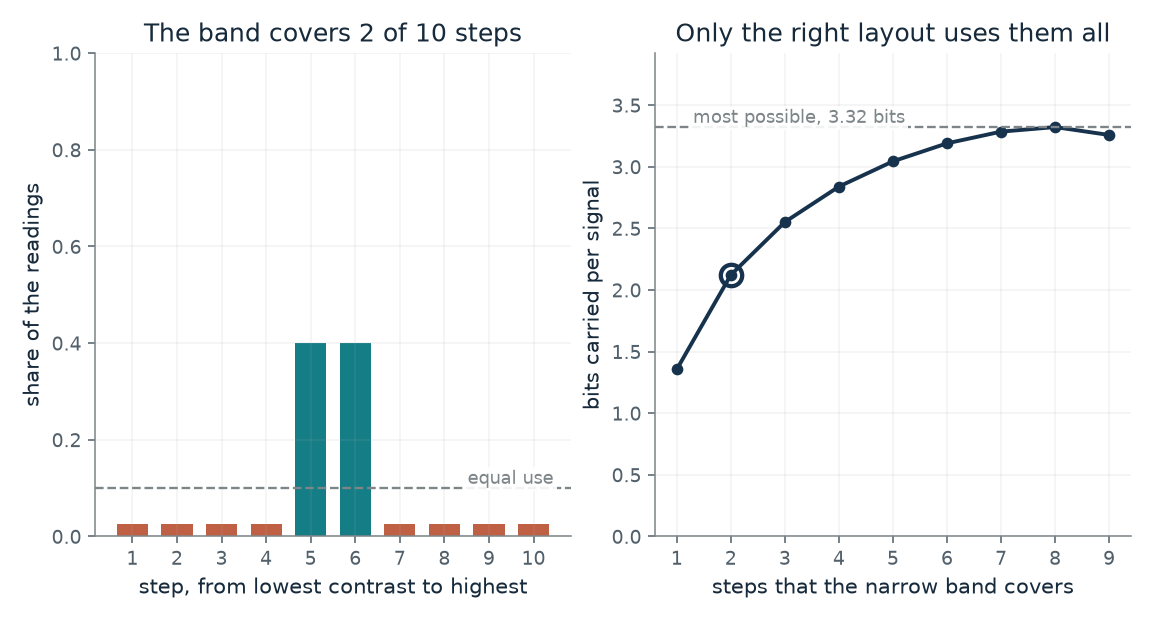

- **Bits carried:** 2.12
- **Most possible, log2 10:** 3.32
- **Share of the most:** 64 percent
- **Busiest step:** 40 percent of readings

With the band covering 2 steps, the busiest step holds 40 percent of the readings and the ten levels carry 2.12 of a possible 3.32 bits. Placement of the steps, not their number, set the shortfall.

Shares: band steps 0.4 each, tail steps 0.025 each. H = -sum p log2 p = 2.12 bits against log2 10 = 3.32.

In [2]:
figure, values, explanation = bits_picture(**{'band_steps': 2, 'band_readings': 800})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How many bits can ten steps carry, and when do they carry them all?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Steps covering the narrow band = 8, Readings in the band (of 1,000) = 800: With eight fine steps in the band and one in each tail, every step holds 100 of the 1,000 readings and the signal carries log2 10 = 3.32 bits. Compare the default, where two steps hold the band and the signal carries 2.12.

**Takeaway:** Ten levels can carry 3.32 bits only if they are used equally often; crowding the readings into a few of them wastes the rest.

**Why it matters:** A sensor or code with a fixed number of levels has a ceiling set by its level count and a shortfall set by how its levels are placed. Placement is the part a designer or a cell can change.

**In brains and behavior:** Laughlin measured contrast in outdoor scenes and the response of fly cells; the ten-level drawing in his note is an illustration, and no bits were counted in a real cell.

**In machines:** Any quantizer or code with M levels has the same ceiling, log2 M bits, and reaches it only when its levels are used equally often.

**Where it applies:** Ten equally distinguishable levels, no noise, and readings spread evenly within the band steps and within the tail steps. This is the capacity of an idealized signal, not a measurement of the fly cell.

**Check your understanding:** How many bits can 16 equally used levels carry, and how many levels do 5 bits need?

<details><summary>Show the answer</summary>

log2 16 = 4 bits. Five bits need 2^5 = 32 equally used levels.

</details>

*Source: Chapter 3, A cell spent its few steps where the world was crowded. Book formula and the chapter's constructed 1,000-reading example (800 in a narrow band, 100 in each tail). Laughlin did not count ten steps in a real cell; the ten levels are an illustration. Spreading band and tail readings evenly inside their steps is this companion's simplification.*

## C03-D02: What does the share-at-or-below rule buy over evenly spaced steps?

If contrast is mostly small, how does a response built from the share of readings at or below each contrast compare with one spaced evenly across the range?

Where readings crowd, a small change in contrast passes many readings, so the share at or below climbs fast and the response with it. Each response step then catches the same share of readings. A straight-line response gives the middle of the range the same number of steps as the far tails, which almost nothing visits.

$$
r(c)=r_{\max}\,F(c),\qquad F(c)=P(C\le c)
$$

**Symbols:** c: one contrast, a change as a fraction of its surroundings; C: the contrast the world hands the cell at random; F(c): share of readings at or below c, a number from 0 to 1; r_max, r(c): the top response, and the response to contrast c

**Predict before looking:** An evenly spaced response clips the extremes if its range is too narrow and leaves its end steps idle if too wide. Predict which half-range, from 0.5 to 8, carries the most bits.

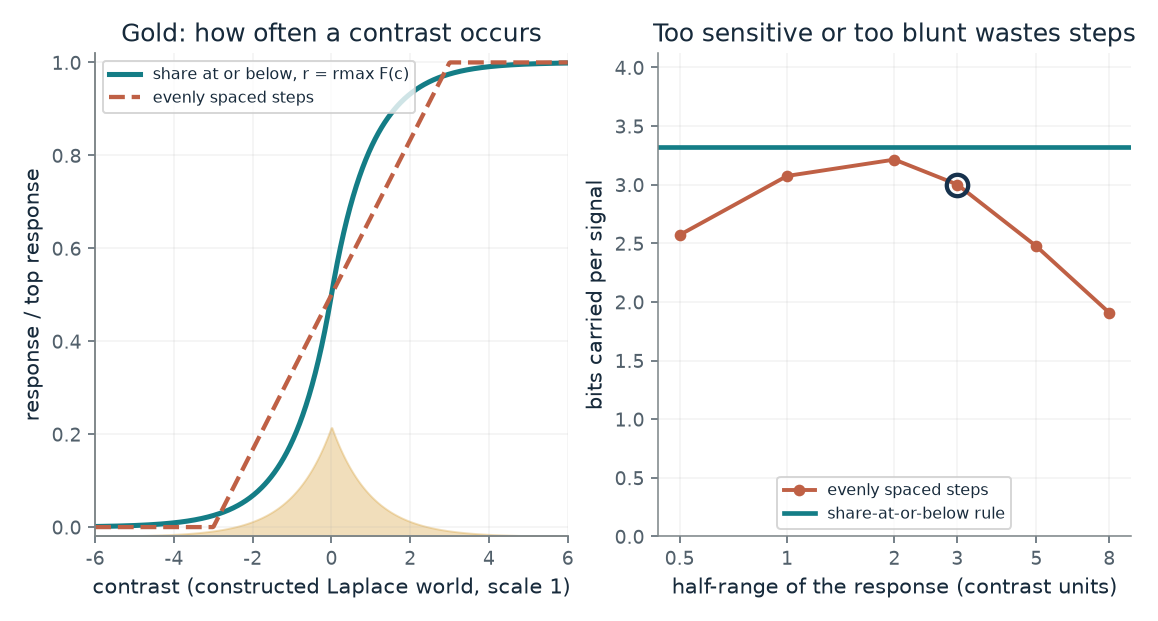

- **Bits, evenly spaced:** 3
- **Bits, share rule:** 3.32
- **Readings clipped at an end:** 5 percent
- **Levels:** 10

With a half-range of 3 the evenly spaced response carries 3 of 3.32 bits and is a middling compromise. The share-at-or-below curve uses every step 10 percent of the time for any scale of world.

Clipped fraction = exp(-3) = 0.0498. Entropy of the 10 step probabilities = 3 bits; the rule gives log2 10 = 3.32.

In [3]:
figure, values, explanation = cumulative_rule_picture(**{'half_range': 3, 'levels': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does the share-at-or-below rule buy over evenly spaced steps?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Half-range of the evenly spaced response = 0.5, Number of response steps = 10: A half-range of 0.5 clips about 61 percent of readings into the end steps and carries 2.57 bits. The best evenly spaced range here is 2 (3.21 bits); only the share-at-or-below curve reaches 3.32 whatever the scale of the world.

**Takeaway:** Making the response follow the share of readings at or below each contrast uses every step equally often, so it carries log2 M bits for any scale of world; an evenly spaced response must be tuned to the scale and still falls short.

**Why it matters:** The rule turns a measured world into a predicted response curve, which Laughlin could then check against a cell. A machine can do the same with a measured input distribution, which is how a photo's brightness values are spread across the available range.

**In brains and behavior:** Laughlin's cell curve and his cumulative curve were both S shapes that matched by eye in six cells of one class; no fit statistic or bits were reported.

**In machines:** Histogram equalization applies the same share-at-or-below curve to spread an image's brightness values. The match is in the curve alone, and it does not mean the cell computes like an image program.

**Where it applies:** Continuous input, zero response floor, equal-sized response steps, equally steady response at every level and information as the only goal; these are the rule's assumptions, not findings of Laughlin's. The linear comparison clips contrasts beyond its half-range into the end steps.

**Check your understanding:** For F(c) = c^2 on the unit interval, what share of readings fall in each of four equal response steps?

<details><summary>Show the answer</summary>

Each step has probability 1/4, so 0.25 each and entropy 2 bits. A response r = rmax F(C) is uniform whatever F is, as long as F is the input's own cumulative curve.

</details>

*Source: Chapter 3, A cell spent its few steps where the world was crowded. Book formula. The world here is a constructed Laplace distribution of contrast with scale 1 (the shape the chapter uses for a later example), not Laughlin's 15,000 readings, which the chapter does not tabulate. The evenly spaced comparison is the companion's own.*

## C03-D03: Does telling inputs apart give the same layout as rebuilding them?

If a later stage must rebuild each contrast closely, where should the step boundaries go compared with the equal-use layout?

When a miss costs its size squared, a rare large contrast that lands in a wide step is expensive, so the layout gives it finer steps than equal use would. The cost is that the middle steps get wider than they need to be to tell commonplace readings apart, and the code carries fewer bits.

$$
\text{equal use: } b_k=F^{-1}(k/M),\qquad \text{rebuild: } \min \sum_{i}\int_{\text{step } i}(c-q_i)^2 f(c)\,dc
$$

**Symbols:** b_k: the k-th boundary between steps, chosen so each step holds 1/M of the readings; q_i: the contrast the receiver assumes when step i is signaled; f(c): the input density; here Laplace with scale 1, f(c) = exp(-|c|) / 2; M: number of steps

**Predict before looking:** Predict whether squared-error boundaries sit nearer to the middle or farther out than the equal-use boundaries, and by about how much the squared error of a ten-step code changes.

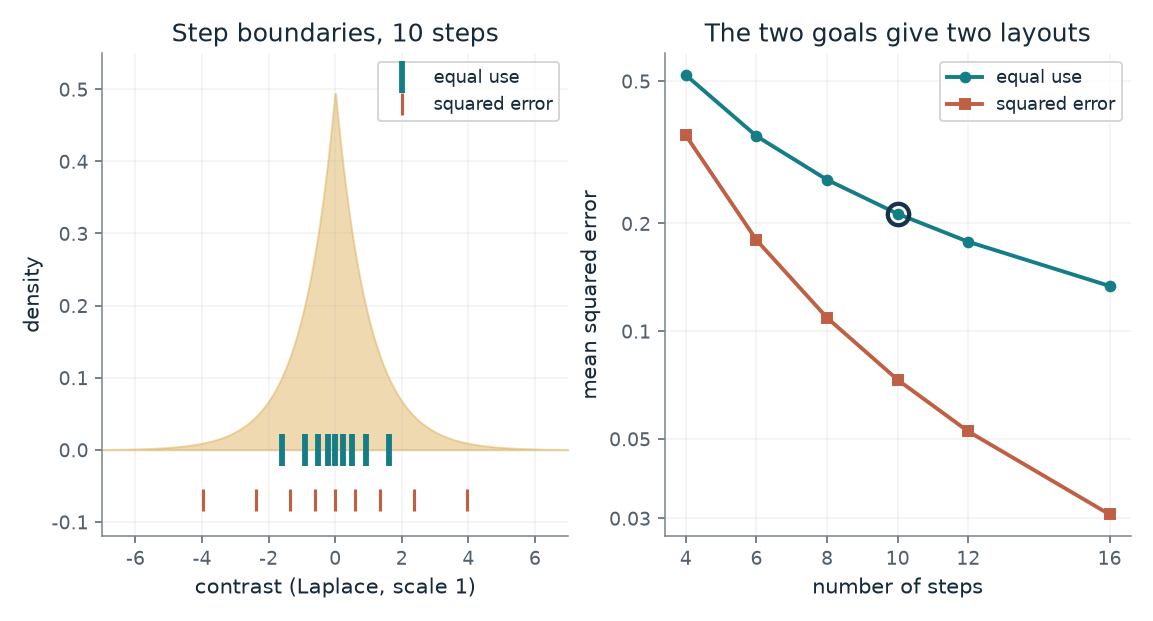

- **Outermost boundary:** 1.61
- **Bits carried:** 3.32
- **Squared error:** 0.213
- **Squared error of the other layout:** 0.0731

With 10 steps, the equal use layout puts its outermost boundary at 1.61 and has squared error 0.213, against 0.0731 for the other layout. Equal use carries 3.32 bits; the squared-error layout trades some of that for a smaller miss on large contrasts.

Equal-use boundaries are the quantiles F^-1(k / M), where F^-1(u) = ln(2u) for u below 0.5 and -ln(2(1 - u)) above. Squared-error boundaries sit midway between neighboring centroids at convergence.

In [4]:
figure, values, explanation = quantizer_picture(**{'levels': 10, 'design': 'equal use'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Does telling inputs apart give the same layout as rebuilding them?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Number of steps = 10, Layout highlighted = squared error: The squared-error layout reaches out to 3.97 where equal use stops at 1.61, and the two end steps hold under 1 percent each. Its squared error is 0.0731 against 0.213, about 2.9 times smaller, at a cost of 0.47 bits (2.85 against 3.32).

**Takeaway:** Telling inputs apart and rebuilding them closely are two goals, and they give two layouts; a third goal, serving a task, would need its own cost.

**Why it matters:** A code is good or bad relative to what the next stage does with it. Equal use maximizes information; it does not minimize the cost of a large miss.

**In brains and behavior:** The note does not say what a fly's later stages need, so nothing here says which layout the fly uses.

**In machines:** A quantizer designer picks the layout by the cost to be minimized: equal use for telling inputs apart, squared-error design for rebuilding them.

**Where it applies:** Laplace contrast with scale 1, squared error as the cost, and each step's rebuilt value set to the mean of the readings in it. The result is not claimed for other distributions or costs, and it says nothing about what a fly's later stages need.

**Check your understanding:** For four equal-use steps on a Laplace density with scale 1, what are the three boundaries? Use F^-1(u) = ln(2u) for u below 0.5.

<details><summary>Show the answer</summary>

The quantiles at 0.25, 0.5 and 0.75: ln(0.5) = -0.693, 0, and 0.693.

</details>

*Source: Chapter 3, Counting information says nothing about what the fly needs. The chapter's own ten-step Laplace example: equal-use boundaries at plus or minus 0.22, 0.51, 0.92 and 1.61 and squared-error boundaries at plus or minus 0.60, 1.35, 2.37 and 3.97. The companion recomputes these and adds other step counts. The chapter calls the comparison this book's calculation for one distribution and one cost.*

## C03-D04: Why must a response curve stretch when the spread of its input changes?

If a cell's velocity input doubles in spread, what does it do to a curve that was best before?

Stretching the input and the curve together changes nothing about which response step each reading lands in. So the bits carried are a function of one number, the width divided by the spread, and the best width scales with the spread. The three curves on the right lie exactly on top of each other for that reason.

$$
p_k=\Phi\!\left(\frac{w\,\ln\frac{k}{M-k}}{\sigma}\right)-\Phi\!\left(\frac{w\,\ln\frac{k-1}{M-k+1}}{\sigma}\right),\qquad H=-\sum_k p_k\log_2 p_k
$$

**Symbols:** sigma: spread of the input velocity (normal, mean 0); w: width of the cell's S-shaped curve, in velocity units; p_k: share of the time response step k is used, for M = 10 equal response steps; Phi: the standard normal cumulative curve; H: bits carried per signal; it depends only on w / sigma

**Predict before looking:** A curve of width 2 is close to best when the velocity spread is 4. If the spread doubles to 8 and the curve stays put, predict whether it loses a little or a lot of the 3.32 bits.

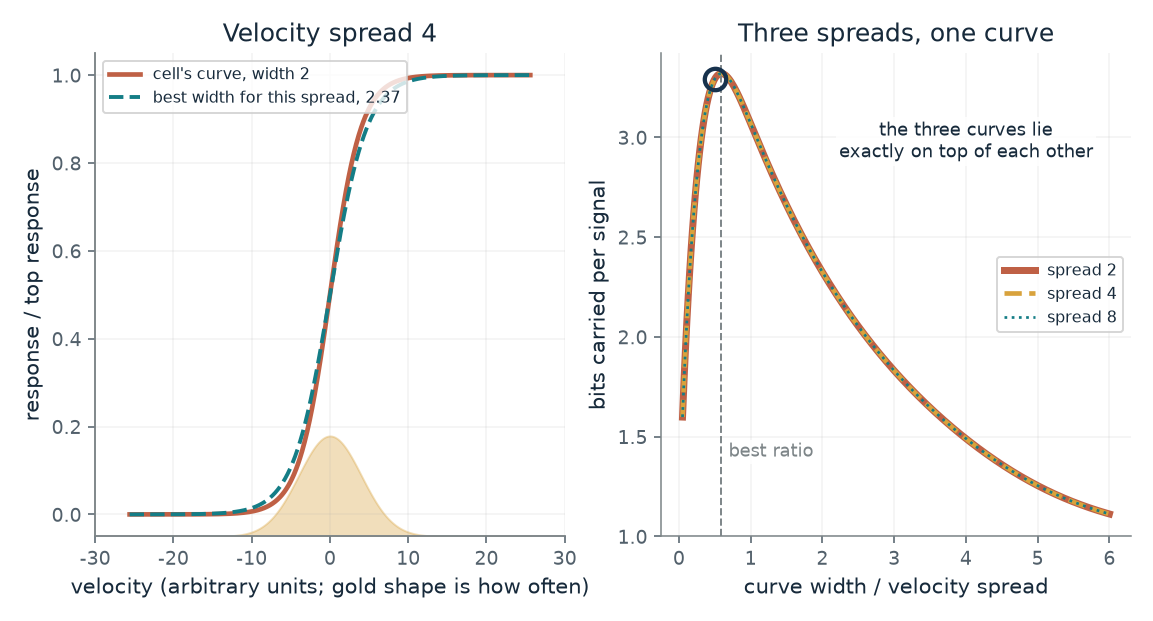

- **Bits carried:** 3.29
- **Bits at the best width:** 3.32
- **Width / spread:** 0.5
- **Best width / spread:** 0.592

At spread 4 a curve of width 2 carries 3.29 bits, against 3.32 at the best width, 2.37. The best width is 0.592 times the spread whatever the spread, so the curve must stretch in proportion.

Boundaries in velocity are width x ln(k/(10 - k)); each step's probability is a difference of normal cumulative values at boundary / 4. Width / spread = 0.5 gives 3.29 bits.

In [5]:
figure, values, explanation = rescaling_picture(**{'spread': 4, 'width': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why must a response curve stretch when the spread of its input changes?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Velocity spread = 8, Width of the cell's curve = 2: At spread 8 a curve of width 2 carries 2.80 bits, about 0.52 below the 3.32 reached at the best width, 4.73. The best width is 0.59 times the spread, so doubling the spread doubles the best width.

**Takeaway:** Only the ratio of curve width to input spread matters, so keeping information high across spreads means stretching the curve in proportion, which is what H1 was reported to do.

**Why it matters:** A code fitted to one spread is mismatched when the spread changes, and the fix is to rescale it. A machine whose inputs change scale faces the same question; the chapter notes that neither the sparse-coding model nor the mammography software was tested for it.

**In brains and behavior:** H1, a blowfly motion cell that fires spikes, widened its response curve when the velocity spread widened; curves nearly coincided once velocity was in units of its spread. This is one cell type in one species.

**In machines:** Normalizing an input by its own spread before a fixed code is the machine counterpart of a curve that stretches; this is an engineering practice, not a claim about cells.

**Where it applies:** Noiseless response read out in ten equal steps, normal velocity with mean zero, and a logistic curve family. The paper's own information test was a calculation on the measured H1 curve for the measured input, not this one, and the other stretches were simulated, not recorded. The paper reports the rescaling broke down at very large spreads.

**Check your understanding:** The best width is about 2.37 at spread 4. What is the best width at spread 8, and at spread 2?

<details><summary>Show the answer</summary>

Best width / spread is fixed at about 0.59, so the best widths are about 4.73 at spread 8 and 1.18 at spread 2: they scale with the spread.

</details>

*Source: Chapter 3, A motion cell stretched its curve when motion changed. Companion calculation in the spirit of the chapter's description of Brenner and colleagues (2000). The chapter reports no formula, no curve family and no bit values; the logistic curve, the normal velocity and the ten equal response steps are made up here.*

## C03-D05: When does a less exact rebuild beat a more exact one?

One code rebuilds a patch more exactly but uses many elements; another is less exact but sparse. Which does the objective prefer?

The first term wants an exact rebuild, and the second wants few or weak elements. A code that is cheap on one is dear on the other, so the weight lambda decides. With a lambda of zero the second term vanishes, and the more exact code wins.

$$
E=\left\|I-\sum_i a_i\phi_i\right\|^2+\lambda\sum_i S(a_i)
$$

**Symbols:** I: the image patch; phi_i, a_i: learned image element i and how strongly it is used; S: the penalty on element use; lambda: nonnegative weight on the penalty

**Predict before looking:** At lambda 0 the exact rebuild wins. Predict the value of lambda above which the sparse rebuild (error 2, penalty 1) starts to win.

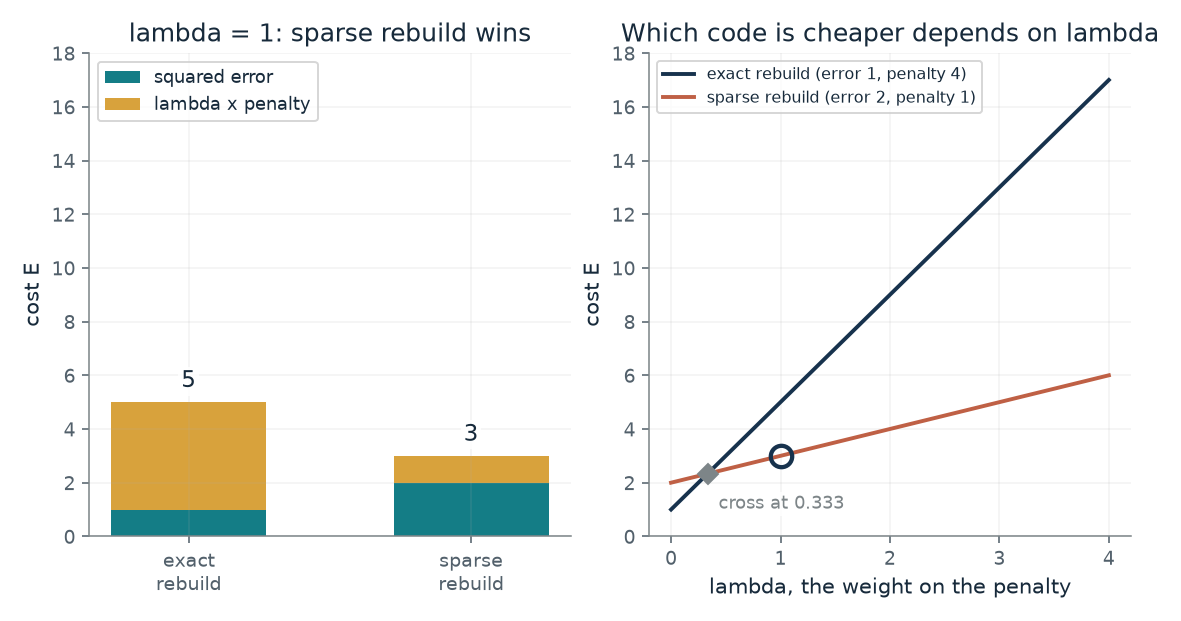

- **Cost, exact rebuild:** 5
- **Cost, sparse rebuild:** 3
- **Cheaper:** sparse rebuild
- **Crossover lambda:** 0.333

At lambda 1 the exact rebuild costs 5 and the sparse rebuild costs 3, so the model prefers the sparse rebuild. The two cost the same at lambda = 0.333; the less exact code wins above that.

Exact: 1 + 1 x 4 = 5. Sparse: 2 + 1 x 1 = 3. Crossover: 1 + 4 L = 2 + L gives L = 0.333.

In [6]:
figure, values, explanation = sparse_cost_picture(**{'lam': 1, 'sparse_error': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='When does a less exact rebuild beat a more exact one?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Penalty weight lambda = 1, Squared error of the sparse code = 2: At lambda 1 the costs are 5 and 3, so the model prefers the less exact, sparse rebuild. They tie at lambda = 1/3; at lambda 0 the exact rebuild wins.

**Takeaway:** Changing the weight on the penalty changes which code the same arithmetic favors.

**Why it matters:** Any objective that mixes accuracy with a cost on complexity has a weight that decides what counts as good. That weight is a design choice, not a measurement.

**In brains and behavior:** In the study, a demand to be accurate and sparse was enough to make learned elements that looked like simple cells, judged by eye and by two averages; this is partial evidence that such a demand could shape the cells, not proof that it does.

**In machines:** The arithmetic is dictionary learning: a set of elements is built from data under a cost like E. The model's objective is a specification, not a model of behavior.

**Where it applies:** Two made-up codes with stated squared errors and penalties. Olshausen and Field set the balance between the two terms themselves, and the paper had no new recordings from cortex.

**Check your understanding:** With sparse error 2 and penalty 1, and exact error 1 and penalty 4, which code wins at lambda 0.25?

<details><summary>Show the answer</summary>

Exact: 1 + 0.25 x 4 = 2. Sparse: 2 + 0.25 x 1 = 2.25. The exact rebuild still wins because 0.25 is below the crossover 1/3.

</details>

*Source: Chapter 3, A model told to use few elements grew detectors like those in cortex. The chapter's constructed comparison: squared error 1 with penalty 4 against squared error 2 with penalty 1, costs 5 and 3 at lambda 1. The companion adds other lambda values and other errors for the sparse code. The equation is a simplified form of the model's objective, not an established equation for cortex.*

## C03-D06: What does the sparsity penalty do to a patch's coefficients?

Given the strength each element would need to rebuild a patch exactly, how many elements stay active as the penalty grows?

With an orthonormal dictionary, each coefficient can be chosen on its own. The derivative of (c - a)^2 + lambda |a| is zero at a = c - lambda/2 for a positive c, so a coefficient smaller than lambda/2 is best set to zero and a larger one shrinks by lambda/2. The squared penalty has a derivative that vanishes at zero, so it never forces zeros.

$$
a_i=\operatorname{sign}(c_i)\max\!\left(|c_i|-\tfrac{\lambda}{2},\,0\right)\ \text{for}\ S(a)=|a|,\qquad a_i=\frac{c_i}{1+\lambda}\ \text{for}\ S(a)=a^2
$$

**Symbols:** c_i: strength element i needs to rebuild the patch exactly (made-up values); a_i: strength the code actually uses; lambda: weight on the penalty; S: the penalty shape, absolute value or square

**Predict before looking:** With the absolute-value penalty, predict how many of the eight elements stay active at lambda 2, and which ones.

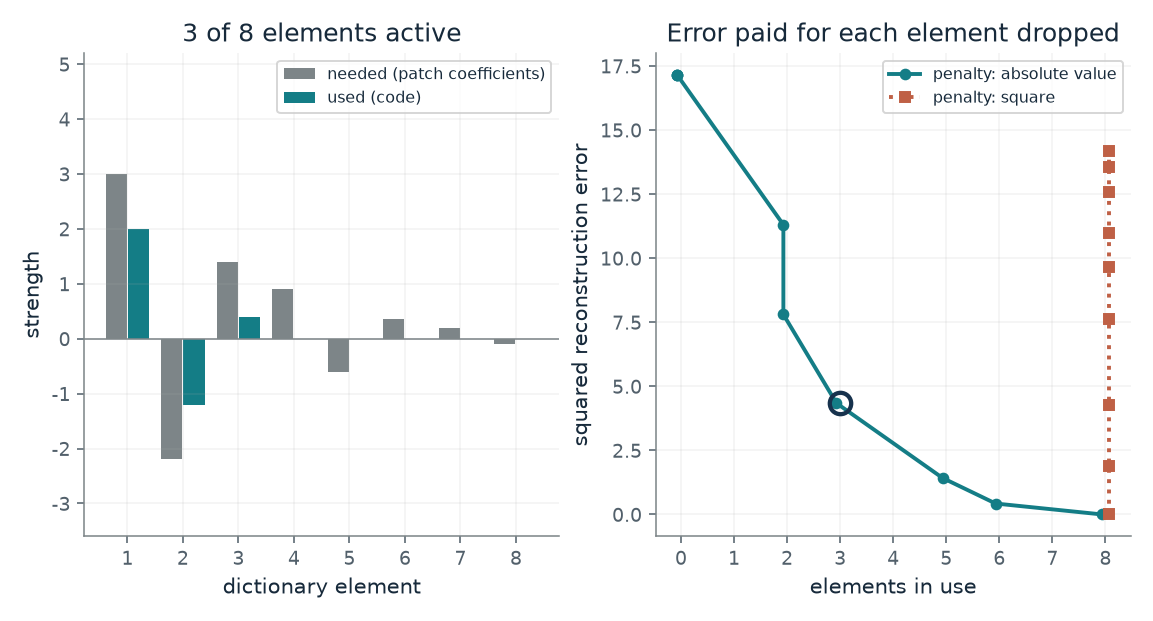

- **Elements active:** 3
- **Squared error:** 4.34
- **Total cost E:** 11.5
- **Energy in the patch:** 17.1

With the absolute-value penalty and lambda 2, every coefficient smaller than lambda/2 = 1 is dropped and the rest shrink by that amount. 3 of 8 elements stay active at a squared error of 4.34.

Squared error = 4.34, penalty term = 2 x 3.6, total E = 11.5.

In [7]:
figure, values, explanation = sparse_toy_picture(**{'lam': 2, 'penalty': 'absolute value'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="What does the sparsity penalty do to a patch's coefficients?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Penalty weight lambda = 2, Penalty shape S = absolute value: Every coefficient below lambda/2 = 1 is dropped, so three of eight stay (3.0, -2.2 and 1.4, each shrunk by 1 to 2.0, -1.2 and 0.4) at a squared error of 4.34. With the square penalty all eight stay at any lambda.

**Takeaway:** A penalty that treats small strengths harshly zeroes them out, and a penalty that grows with the square only shrinks them, so the shape of the penalty decides whether the code is sparse.

**Why it matters:** Few active elements is a goal that has to be written into the cost. Which shape of penalty is used decides whether the result has exact zeros or only small values.

**In brains and behavior:** Most learned elements in the study sat in one place, ran along one direction and picked one size of detail, as simple cortical cells do; the likeness was judged by looking, and the model's elements were about 1.3 times longer than wide against about 2 for the cited cells.

**In machines:** The toy is the coding step of dictionary learning with a fixed dictionary: a specification, not a model of any trained system.

**Where it applies:** A fixed orthonormal dictionary, so minimizing E splits into one-number problems. The paper's elements were learned from 16 by 16 patches of natural images with a different penalty function and without an orthonormality constraint, and the paper did not require other coefficients to be exactly zero.

**Check your understanding:** With the absolute-value penalty and lambda 4, which coefficients of 3.0, -2.2, 1.4 survive and how strong are they?

<details><summary>Show the answer</summary>

The threshold is lambda/2 = 2, so 3.0 becomes 1.0 and -2.2 becomes -0.2, and 1.4 is dropped: two of the three survive.

</details>

*Source: Chapter 3, A model told to use few elements grew detectors like those in cortex. The companion's own toy built on the chapter's objective. The chapter does not state a penalty shape and does not give this closed form. The eight coefficients are made up, and the dictionary is taken as orthonormal so the elements do not overlap. No learning of elements is done here, only the coding step.*

## C03-D07: What do reported sensitivity and specificity mean in counts?

If marks on a mammogram change sensitivity by 2 points and specificity by 3, how many cancers and how many recalls change per 100,000 exams?

Sensitivity applies to the small group with cancer, and specificity applies to the large group without. A 2-point change on about 505 cancers is about 10; a 3-point change on about 99,495 exams without cancer is about 2,985. With the Lehman cancer rate and sensitivity 87.3, the arithmetic recall rates at specificity 90.2 and 87.2 are 10.2 and 13.2 percent, close to Fenton's reported 10.1 and 13.2.

$$
\text{found}=N\,\pi\,s_e,\qquad \text{no-cancer recalls}=N\,(1-\pi)\,(1-s_p)
$$

**Symbols:** N: number of screening exams (100,000 here); pi: cancer rate, 3,159 of 625,625 = 0.00505, from the chapter's counts; s_e: sensitivity, the share of cancers a reading finds; s_p: specificity, the share of examinations without a cancer diagnosis whose reading was negative

**Predict before looking:** Lehman's sensitivity gap is 2 points. Predict whether it is worth more cancers or fewer than 100 per 100,000 exams, and how it compares with the recall change from Fenton's specificity drop of 3 points.

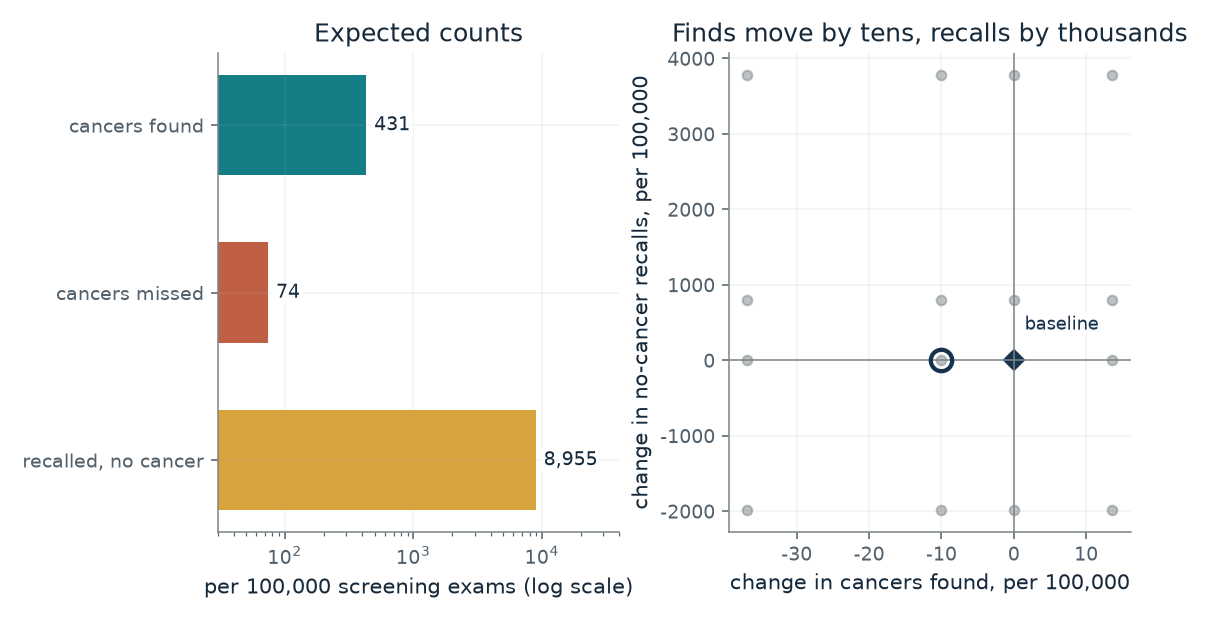

- **Cancers found:** 431
- **Cancers missed:** 74
- **Recalled with no cancer:** 8,955
- **Recall rate:** 9.4 percent

At sensitivity 85.3 and specificity 91 the arithmetic gives about 431 cancers found and 8,955 no-cancer recalls per 100,000 exams, a recall rate of 9.4 percent. Against the baseline, finds change by -10 and no-cancer recalls by +0.

Cancer rate = 3,159 / 625,625 = 0.00505. Cancers per 100,000 = 505. Found = 505 x 0.853 = 431. No-cancer recalls = 99,495 x 0.09 = 8,955.

In [8]:
figure, values, explanation = screening_picture(**{'sensitivity': 85.3, 'specificity': 91.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What do reported sensitivity and specificity mean in counts?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Sensitivity (percent) = 87.3, Specificity (percent) = 87.2: Holding sensitivity at 87.3 and dropping specificity from 91 to 87.2 leaves finds unchanged and adds about 3,781 recalls of women without cancer per 100,000 exams. Two points of sensitivity are only about 10 cancers; the recall rate rises from 9.4 to 13.2 percent.

**Takeaway:** A few points of sensitivity move counts of cancers by tens per 100,000 exams, while a few points of specificity move recalls by thousands, because exams without cancer vastly outnumber the rest.

**Why it matters:** A rate that looks small can be a large count, and a mark that asks for a second look costs attention whether or not it helps. The chapter's studies did not measure that cost; it is an inference.

**In brains and behavior:** The reader is the brain side: a radiologist who must review and dismiss marks, with limited attention. The studies did not measure attention.

**In machines:** The software is the machine side: marks built to flag what a reader might drop. In Lehman's data they were not linked to better accuracy overall.

**Where it applies:** The rates are observational, model-derived estimates from two studies that differ in years and design and are not pooled. Applying one study's cancer rate to the other's specificity is arithmetic for illustration. The studies do not show why marks did not help, and this is not advice about any screening decision.

**Check your understanding:** At a cancer rate of 3,159 per 625,625, about how many cancers are there per 100,000 exams, and how many does a sensitivity of 85.3 percent find?

<details><summary>Show the answer</summary>

3,159 / 625,625 x 100,000 = 505 cancers per 100,000 exams. At 85.3 percent, about 431 are found and 74 are missed.

</details>

*Source: Chapter 3, Software marks on mammograms of 300,000 women were not linked to better readings. Rates from Lehman and colleagues (2015): sensitivity 85.3 percent with the software and 87.3 without, specificity about 91 percent either way, 3,159 cancers in 625,625 exams. Specificity values 87.2 and 90.2 are Fenton and colleagues' (2007), a different study; the values 80, 90 and 93 are dial settings chosen here. The counts are arithmetic, not results from either study.*

## Bring it to your own question

Ask how many distinguishable levels the channel has, how the inputs are distributed, and what the next stage does with the signal. Use the entropy ceiling for the most bits, the share-at-or-below rule when the goal is to tell inputs apart, the squared-error layout when a later stage must rebuild the input, and the sparse objective when few active elements are wanted. For a screening or alerting tool, convert reported rates into counts before judging it.

Use the `mmi-ch03-keeping-what-matters` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.